In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [16]:
df = pd.read_csv("../datos/AB_NYC_2019.csv")
print("Filas y columnas:", df.shape)
print(df.dtypes)
print(df.head())
print(df.describe().round(2).T)
print(df.describe(include="object").T)

Filas y columnas: (48895, 16)
id                                  int64
name                                  str
host_id                             int64
host_name                             str
neighbourhood_group                   str
neighbourhood                         str
latitude                          float64
longitude                         float64
room_type                             str
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                           str
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object
     id                                              name  host_id  \
0  2539                Clean & quiet apt home by the park     2787   
1  2595                             Skylit Midtown Castle     2845   
2  3647               THE VILLAGE OF HARLEM....NEW YORK !     4632   
3  3

/tmp/ipykernel_31274/581546326.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include="object").T)


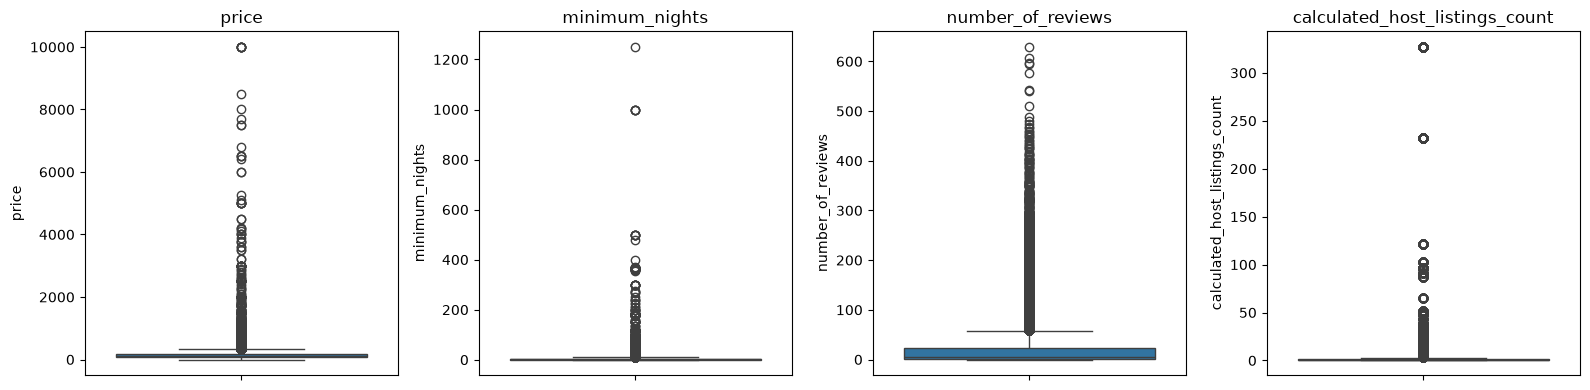

price límite superior: 334.0 outliers: 2972 máximo: 10000
minimum_nights límite superior: 11.0 outliers: 6607 máximo: 1250
number_of_reviews límite superior: 58.5 outliers: 6021 máximo: 629
calculated_host_listings_count límite superior: 3.5 outliers: 7081 máximo: 327
Registros excluidos: 264


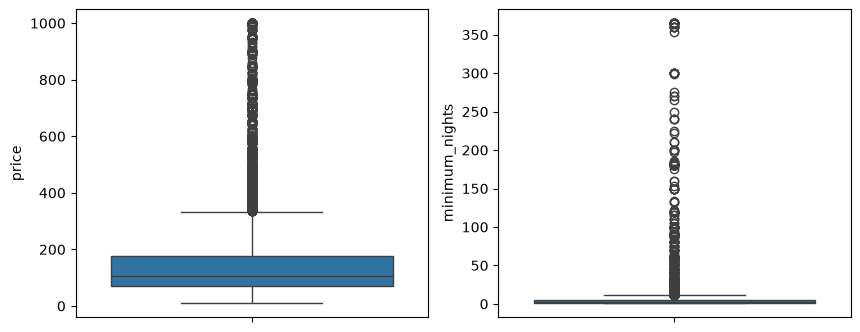

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["price", "minimum_nights", "number_of_reviews", "calculated_host_listings_count"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)
    print(col, "límite superior:", limite, "outliers:", (df[col] > limite).sum(), "máximo:", df[col].max())

df_sin_out = df[(df["price"] > 0) & (df["price"] <= 1000) & (df["minimum_nights"] <= 365)].copy()
print("Registros excluidos:", len(df) - len(df_sin_out))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df_sin_out["price"], ax=axes[0])
sns.boxplot(y=df_sin_out["minimum_nights"], ax=axes[1])
plt.show()


In [19]:
df_sin_out["tiene_resenas"] = df_sin_out["number_of_reviews"] > 0
df_sin_out["noches_ocupadas"] = 365 - df_sin_out["availability_365"]
df_sin_out["ingreso_estimado"] = df_sin_out["price"] * df_sin_out["noches_ocupadas"]
df_sin_out["categoria_precio"] = pd.cut(df_sin_out["price"], bins=[0, 75, 150, 300, 1000],
                                        labels=["Económico", "Medio", "Alto", "Lujo"])

print(df_sin_out[["price", "availability_365", "noches_ocupadas", "ingreso_estimado", "categoria_precio"]].head())
print(df_sin_out["tiene_resenas"].value_counts(normalize=True).round(3))
print(df_sin_out["categoria_precio"].value_counts())

   price  availability_365  noches_ocupadas  ingreso_estimado categoria_precio
0    149               365                0                 0            Medio
1    225               355               10              2250             Alto
2    150               365                0                 0            Medio
3     89               194              171             15219            Medio
4     80                 0              365             29200            Medio
tiene_resenas
True     0.796
False    0.204
Name: proportion, dtype: float64
categoria_precio
Medio        18704
Económico    15232
Alto         11578
Lujo          3117
Name: count, dtype: int64


In [ ]:
# 1. Precio promedio y mediano por zona
print(df_sin_out.groupby("neighbourhood_group")["price"].agg(["count", "mean", "median"]).round(1).sort_values("mean", ascending=False))
# 2. Precio mediano por tipo de habitación
print(df_sin_out.groupby("room_type")["price"].agg(["count", "median"]))

# 3. Tipo de habitación por zona (porcentaje)
print((df_sin_out.groupby("neighbourhood_group")["room_type"].value_counts(normalize=True) * 100).round(1).unstack())
# 4. Barrios más caros (mínimo 50 publicaciones)
barrios = df_sin_out.groupby("neighbourhood")["price"].agg(["count", "mean"])
print(barrios[barrios["count"] >= 50].sort_values("mean", ascending=False).head(10).round(1))

# 5. Disponibilidad e ingreso estimado por zona
print(df_sin_out.groupby("neighbourhood_group")[["availability_365", "ingreso_estimado"]].mean().round(1))